## Task

1. Write a NumPy program to test element-wise for NaN of a given array.
2. Write a NumPy program to test element-wise for complex number, real number of a given array. Also test whether a given number is a scalar type or not.
3. Write a NumPy program to test whether two arrays are element-wise equal within a tolerance.
4. Write a NumPy program to create an element-wise comparison (greater, greater_equal, less and less_equal) of two given arrays.
5. Write a NumPy program to create an element-wise comparison (equal, equal within a tolerance) of two given arrays.
6. Write a NumPy program to create an array with the values 1, 7, 13, 105 and determine the size of the memory occupied by the array.
7. In the code cell below, write the code to get and display the 55th row in the dataframe df.
8. In the code cell below write the code to display the first 10 rows of the dataframe <code>df</code>.
9. In the code cell below, select and display the first eight rows from the <code>'Country'</code> and <code>'TB deaths'</code> columns.
10. In the code cell below write code to find all the rows in <code>df</code> where TB deaths exceed 10000.
11. In the code cell below find  all the countries where the Population (1000s) is **less than or equal to** 50000 **or** TB deaths are **greater than or equal to** 20000.
                                             

### Solutions: Tasks 1–11

In [49]:
import numpy as np
import pandas as pd

# Task 1: element-wise NaN test
a = np.array([1, 0, np.nan, np.inf])
print("Array:", a)
print("Is NaN?:", np.isnan(a))

Array: [ 1.  0. nan inf]
Is NaN?: [False False  True False]


In [50]:
# Task 2: complex / real / scalar tests
a = np.array([1 + 1j, 1 + 0j, 4.5, 3, 2, 2j])
print("Array:", a)
print("Is complex?:", np.iscomplex(a))
print("Is real?   :", np.isreal(a))
print("3.1 is scalar?   ", np.isscalar(3.1))
print("[3.1] is scalar? ", np.isscalar([3.1]))

Array: [1. +1.j 1. +0.j 4.5+0.j 3. +0.j 2. +0.j 0. +2.j]
Is complex?: [ True False False False False  True]
Is real?   : [False  True  True  True  True False]
3.1 is scalar?    True
[3.1] is scalar?  False


In [51]:
# Task 3: equality within a tolerance
print(np.allclose([1e10, 1e-7], [1.00001e10, 1e-8]))   # False: 1e-7 vs 1e-8 differ too much (atol=1e-8)
print(np.allclose([1e10, 1e-8], [1.00001e10, 1e-9]))   # True : within default rtol=1e-5, atol=1e-8
print(np.allclose([1e10, 1e-8], [1.0001e10, 1e-9]))    # False: rel. diff 1e-4 > rtol
print(np.allclose([1.0, np.nan], [1.0, np.nan]))                  # False (NaN != NaN)
print(np.allclose([1.0, np.nan], [1.0, np.nan], equal_nan=True))  # True

False
True
False
False
True


In [52]:
# Task 4: element-wise comparisons
x = np.array([3, 5, 7])
y = np.array([2, 5, 9])
print("x:", x, " y:", y)
print("greater       :", np.greater(x, y))
print("greater_equal :", np.greater_equal(x, y))
print("less          :", np.less(x, y))
print("less_equal    :", np.less_equal(x, y))

x: [3 5 7]  y: [2 5 9]
greater       : [ True False False]
greater_equal : [ True  True False]
less          : [False False  True]
less_equal    : [False  True  True]


In [53]:
# Task 5: equality and equality within a tolerance
x = np.array([72, 79, 85, 90, 150, -135, 120, -10, 60, 100])
y = np.array([72, 79, 85, 90, 150, -135, 120, -10, 60, 100.000001])
print("equal                    :", np.equal(x, y))
print("equal within tolerance   :", np.isclose(x, y))

equal                    : [ True  True  True  True  True  True  True  True  True False]
equal within tolerance   : [ True  True  True  True  True  True  True  True  True  True]


In [54]:
# Task 6: array of 1, 7, 13, 105 and its memory footprint
arr = np.array([1, 7, 13, 105])
print("Array:", arr, "| dtype:", arr.dtype)
print("Size of memory occupied:", arr.size * arr.itemsize, "bytes")   # same as arr.nbytes

Array: [  1   7  13 105] | dtype: int64
Size of memory occupied: 32 bytes


In [55]:
   from dotenv import find_dotenv, dotenv_values
   print(list(dotenv_values(find_dotenv(usecwd=True)).keys()))

['SQL_SERVER_NAME', 'SQL_SERVER_DATABASE', 'SQL_READONLY_USERNAME', 'SQL_READONLY_PASSWORD']


In [56]:
import os, pathlib
from dotenv import find_dotenv, dotenv_values

root = pathlib.Path.cwd()
print("Working folder:", root)
print("Files here:", [p.name for p in root.iterdir()])
print("dotenv found:", find_dotenv(usecwd=True))
print("Keys in .env:", list(dotenv_values(find_dotenv(usecwd=True)).keys()))

Working folder: C:\Users\user\OneDrive\Desktop\dataraflow\db
Files here: ['.env', '.ipynb_checkpoints', 'dataraflow_db.py', 'Take_Home_completed.ipynb', 'Take_Home_completed.md', '__pycache__']
dotenv found: C:\Users\user\OneDrive\Desktop\dataraflow\db\.env
Keys in .env: ['SQL_SERVER_NAME', 'SQL_SERVER_DATABASE', 'SQL_READONLY_USERNAME', 'SQL_READONLY_PASSWORD']


**Tasks 7–11** use the WHO TB dataframe `df`. It comes from the cohort database (`week06.who_pop_tb_all`). Run the SQL-setup cell further down first, or just run this one:

In [57]:
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

df = run_query("SELECT * FROM week06.who_pop_tb_all")
print(df.shape)
print(df.columns.tolist())
df.head()

(194, 3)
['Country', 'Population (1000s)', 'TB deaths']


,Country,Population (1000s),TB deaths
0,Afghanistan,30552,13000.00
1,Albania,3173,20.00
2,Algeria,39208,5100.00
3,Andorra,79,0.26
4,Angola,21472,6900.00


In [58]:
# Task 7: the 55th row (position 55 -> index 54, because Python counts from 0)
df.iloc[54]

Country               El Salvador
Population (1000s)           6340
TB deaths                    61.0
Name: 54, dtype: object

In [59]:
# Task 8: first 10 rows
df.head(10)

,Country,Population (1000s),TB deaths
0,Afghanistan,30552,13000.00
1,Albania,3173,20.00
2,Algeria,39208,5100.00
3,Andorra,79,0.26
4,Angola,21472,6900.00
5,Antigua and Barbuda,90,1.20
6,Argentina,41446,570.00
7,Armenia,2977,170.00
8,Australia,23343,45.00
9,Austria,8495,29.00


In [60]:
# Task 9: first eight rows of 'Country' and 'TB deaths'
df[['Country', 'TB deaths']].head(8)

,Country,TB deaths
0,Afghanistan,13000.00
1,Albania,20.00
2,Algeria,5100.00
3,Andorra,0.26
4,Angola,6900.00
5,Antigua and Barbuda,1.20
6,Argentina,570.00
7,Armenia,170.00


In [61]:
# Task 10: rows where TB deaths exceed 10000
df[df['TB deaths'] > 10000]

,Country,Population (1000s),TB deaths
0,Afghanistan,30552,13000.0
13,Bangladesh,156595,80000.0
36,China,1393337,41000.0
47,Democratic Republic of the Congo,67514,46000.0
58,Ethiopia,94101,30000.0
77,India,1252140,240000.0
78,Indonesia,249866,64000.0
100,Madagascar,22925,12000.0
115,Mozambique,25834,18000.0
116,Myanmar,53259,26000.0


In [62]:
# Task 11: Population (1000s) <= 50000 OR TB deaths >= 20000 -> countries
# (each condition in its own brackets; | is "or", & is "and")
df[(df['Population (1000s)'] <= 50000) | (df['TB deaths'] >= 20000)]['Country']

0                             Afghanistan
1                                 Albania
2                                 Algeria
3                                 Andorra
4                                  Angola
                      ...                
188                               Vanuatu
189    Venezuela (Bolivarian Republic of)
191                                 Yemen
192                                Zambia
193                              Zimbabwe
Name: Country, Length: 180, dtype: str

## Assignment

1. Write a Python program to create and display a one-dimensional array-like object containing an array of data using Pandas module.


2. Write a Python program to convert a Panda module Series to Python list and it's type.


3. Write a Python program to add, subtract, multiple and divide two Pandas Series.
Sample Series: [2, 4, 6, 8, 10], [1, 3, 5, 7, 9]


4. Write a Python program to get the largest integer smaller or equal to the division of the inputs.
Sample Series: [2, 4, 6, 8, 10], [1, 3, 5, 7, 9]


5. Write a Python program to convert a dictionary to a Pandas series.
Sample Series:
Original dictionary:
{'a': 100, 'b': 200, 'c': 300, 'd': 400, 'e': 800}
Converted series:
a 100
b 200
c 300
d 400
e 800
dtype: int64


6. Write a Python program to convert a NumPy array to a Pandas series.
Sample Series:
NumPy array:
[10 20 30 40 50]
Converted Pandas series:
0 10
1 20
2 30
3 40
4 50
dtype: int64


7. Write a Python program to change the data type of given a column or a Series.
Sample Series:
Original Data Series:
0 100
1 200
2 python
3 300.12
4 400
dtype: object
Change the said data type to numeric:
0 100.00
1 200.00
2 NaN
3 300.12
4 400.00
dtype: float64


8. Write a Python Pandas program to convert the first column of a DataFrame as a Series.
Sample Output:
Original DataFrame
col1 col2 col3
0 1 4 7
1 2 5 5
2 3 6 8
3 4 9 12
4 7 5 1
5 11 0 11
1st column as a Series:
0 1
1 2
2 3
3 4
4 7
5 11
Name: col1, dtype: int64
<class 'pandas.core.series.Series'>


9. Write a Pandas program to convert a given Series to an array.
Sample Output:
Original Data Series:
0 100
1 200
2 python
3 300.12
4 400
dtype: object
Series to an array
['100' '200' 'python' '300.12' '400']



 
10. Write a Pandas program to convert Series of lists to one Series.
Sample Output:
Original Series of list
0 [Red, Green, White]
1 [Red, Black]
2 [Yellow]
dtype: object
One Series
0 Red
1 Green
2 White
3 Red
4 Black
5 Yellow
dtype: object


11. Write a Pandas program to sort a given Series.
Sample Output:
Original Data Series: 0 100
1 200
2 python
3 300.12
4 400
dtype: object
0 100
1 200
3 300.12
4 400
2 python
dtype: object


12. Write a Pandas program to add some data to an existing Series.
Sample Output:
Original Data Series:
0 100
1 200
2 python
3 300.12
4 400
dtype: object
Data Series after adding some data:
0 100
1 200
2 python
3 300.12
4 400
0 500
1 php
dtype: object

### Solutions: Assignment 1–12

In [63]:
import numpy as np
import pandas as pd

# 1. One-dimensional array-like object with Pandas
s = pd.Series([2, 4, 6, 8, 10])
print(s)

0     2
1     4
2     6
3     8
4    10
dtype: int64


In [64]:
# 2. Series -> Python list (and its type)
ds = pd.Series([1, 2, 3, 4, 5])
lst = ds.tolist()
print(lst, type(lst))

[1, 2, 3, 4, 5] <class 'list'>


In [65]:
# 3. Arithmetic on two Series
s1 = pd.Series([2, 4, 6, 8, 10])
s2 = pd.Series([1, 3, 5, 7, 9])
print("Add:\n", s1 + s2)
print("Subtract:\n", s1 - s2)
print("Multiply:\n", s1 * s2)
print("Divide:\n", s1 / s2)

Add:
 0     3
1     7
2    11
3    15
4    19
dtype: int64
Subtract:
 0    1
1    1
2    1
3    1
4    1
dtype: int64
Multiply:
 0     2
1    12
2    30
3    56
4    90
dtype: int64
Divide:
 0    2.000000
1    1.333333
2    1.200000
3    1.142857
4    1.111111
dtype: float64


In [66]:
# 4. Floor division: largest integer <= the division of the inputs
print(s1 // s2)

0    2
1    1
2    1
3    1
4    1
dtype: int64


In [67]:
# 5. Dictionary -> Series
d = {'a': 100, 'b': 200, 'c': 300, 'd': 400, 'e': 800}
print("Original dictionary:", d)
print("Converted series:\n", pd.Series(d))

Original dictionary: {'a': 100, 'b': 200, 'c': 300, 'd': 400, 'e': 800}
Converted series:
 a    100
b    200
c    300
d    400
e    800
dtype: int64


In [68]:
# 6. NumPy array -> Series
arr = np.array([10, 20, 30, 40, 50])
print("NumPy array:", arr)
print("Converted Pandas series:\n", pd.Series(arr))

NumPy array: [10 20 30 40 50]
Converted Pandas series:
 0    10
1    20
2    30
3    40
4    50
dtype: int64


In [69]:
# 7. Change dtype to numeric (bad values become NaN)
s = pd.Series(['100', '200', 'python', '300.12', '400'])
print("Original:\n", s)
print("As numeric:\n", pd.to_numeric(s, errors='coerce'))

Original:
 0       100
1       200
2    python
3    300.12
4       400
dtype: str
As numeric:
 0    100.00
1    200.00
2       NaN
3    300.12
4    400.00
dtype: float64


In [70]:
# 8. First column of a DataFrame as a Series
d = {'col1': [1, 2, 3, 4, 7, 11], 'col2': [4, 5, 6, 9, 5, 0], 'col3': [7, 5, 8, 12, 1, 11]}
df1 = pd.DataFrame(d)
print("Original DataFrame\n", df1)
first = df1.iloc[:, 0]
print("1st column as a Series:\n", first)
print(type(first))

Original DataFrame
    col1  col2  col3
0     1     4     7
1     2     5     5
2     3     6     8
3     4     9    12
4     7     5     1
5    11     0    11
1st column as a Series:
 0     1
1     2
2     3
3     4
4     7
5    11
Name: col1, dtype: int64
<class 'pandas.Series'>


In [71]:
# 9. Series -> array
s = pd.Series(['100', '200', 'python', '300.12', '400'])
print("Original Data Series:\n", s)
print("Series to an array:", np.array(s.tolist()))

Original Data Series:
 0       100
1       200
2    python
3    300.12
4       400
dtype: str
Series to an array: ['100' '200' 'python' '300.12' '400']


In [72]:
# 10. Series of lists -> one Series
s = pd.Series([['Red', 'Green', 'White'], ['Red', 'Black'], ['Yellow']])
print("Original Series of list\n", s)
print("One Series\n", s.explode().reset_index(drop=True))

Original Series of list
 0    [Red, Green, White]
1           [Red, Black]
2               [Yellow]
dtype: object
One Series
 0       Red
1     Green
2     White
3       Red
4     Black
5    Yellow
dtype: str


In [73]:
# 11. Sort a Series (values are mixed types, so compare them as text)
s = pd.Series([100, 200, 'python', 300.12, 400])
print("Original Data Series:\n", s)
print(s.sort_values(key=lambda x: x.astype(str)))

Original Data Series:
 0       100
1       200
2    python
3    300.12
4       400
dtype: object
0       100
1       200
3    300.12
4       400
2    python
dtype: object


In [74]:
# 12. Add data to an existing Series
# (Series.append was removed in pandas 2.0, so pd.concat is used)
s = pd.Series([100, 200, 'python', 300.12, 400])
new = pd.Series([500, 'php'])
print("Data Series after adding some data:\n", pd.concat([s, new]))

Data Series after adding some data:
 0       100
1       200
2    python
3    300.12
4       400
0       500
1       php
dtype: object


## Assessment

#### The datasets now live in the cohort database (schema `week06`)

The six airport weather datasets are the tables:

```
week06.beijing_pek_2014, week06.brasilia_bsb_2014, week06.capetown_cpt_2014,
week06.delhi_del_2014,   week06.london_2014,       week06.moscow_svo_2014
```

Pull them with SQL and explore them — see **`Data Access (SQL).md`** in this week's folder
for the connection snippet and worked examples. For example:

```python
from db.dataraflow_db import run_query
london = run_query("SELECT * FROM week06.london_2014")
```

Run your analysis on them, and detail your findings below as much as you can.


### Weather analysis: six airports, 2014

In [75]:
import sys, pathlib, time
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))

from db import dataraflow_db
import pandas as pd

def run_query(sql, retries=4):
    """Same as the course helper, but resets a broken connection and retries."""
    for attempt in range(retries):
        try:
            return pd.read_sql(sql, dataraflow_db.get_engine())
        except Exception as e:
            print(f"Attempt {attempt + 1} failed: {type(e).__name__}. Resetting connection...")
            dataraflow_db.get_engine().dispose()
            time.sleep(10)
    raise RuntimeError("Could not connect after several tries. Check your internet or try a phone hotspot.")

run_query("SELECT 1 AS ok")

,ok
0,1


In [76]:
from db import dataraflow_db
dataraflow_db.get_engine().dispose()

In [77]:
run_query("""
SELECT TABLE_NAME
FROM INFORMATION_SCHEMA.TABLES
WHERE TABLE_SCHEMA = 'week06'
ORDER BY TABLE_NAME
""")

Attempt 1 failed: OperationalError. Resetting connection...


,TABLE_NAME
0,beijing_pek_2014
1,brasilia_bsb_2014
2,capetown_cpt_2014
3,delhi_del_2014
4,london_2014
5,moscow_svo_2014
6,who_pop_tb_all
7,who_pop_tb_some


In [80]:
# 1. Look at the columns in each city's table
for city, d in raw.items():
    d.columns = d.columns.str.strip()
    print(city, "->", d.columns.tolist()[:4], "...", len(d.columns), "columns")

Beijing -> ['Date', 'Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC'] ... 23 columns
Brasilia -> ['Date', 'Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC'] ... 23 columns
Cape Town -> ['Date', 'Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC'] ... 23 columns
Delhi -> ['Date', 'Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC'] ... 23 columns
London -> ['GMT', 'Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC'] ... 23 columns
Moscow -> ['Date', 'Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC'] ... 23 columns


In [81]:
# 2. Rename each table's first column (the date) to "GMT" and tidy up
for city, d in raw.items():
    d.rename(columns={d.columns[0]: "GMT"}, inplace=True)
    d["GMT"] = pd.to_datetime(d["GMT"], errors="coerce")
    d["city"] = city

weather = pd.concat(raw.values(), ignore_index=True)
print(weather.shape)
print(weather["GMT"].isna().sum(), "dates could not be parsed")
weather.head()

(2190, 24)
0 dates could not be parsed


,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees<br />,city
0,2014-01-01,12,4,-2,-12,-17,-20,44,19,7,...,11.0,5.0,32,16,47.0,0.0,NaN,NaN,291<br />,Beijing
1,2014-01-02,7,0,-6,-6,-9,-13,74,50,28,...,7.0,3.0,18,5,NaN,0.0,NaN,NaN,20<br />,Beijing
2,2014-01-03,9,3,-2,-7,-13,-18,64,32,9,...,13.0,5.0,18,8,NaN,0.0,NaN,NaN,24<br />,Beijing
3,2014-01-04,2,-2,-6,-4,-7,-9,80,68,44,...,5.0,2.0,11,5,NaN,0.0,2.0,NaN,56<br />,Beijing
4,2014-01-05,7,0,-7,-5,-11,-15,80,51,15,...,7.0,3.0,18,10,NaN,0.0,NaN,NaN,18<br />,Beijing


In [82]:
import sys, pathlib, time
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))

from db import dataraflow_db
import pandas as pd
import matplotlib.pyplot as plt

def run_query(sql, retries=4):
    """Course helper plus: reset a broken connection and retry."""
    for attempt in range(retries):
        try:
            return pd.read_sql(sql, dataraflow_db.get_engine())
        except Exception as e:
            print(f"Attempt {attempt + 1} failed: {type(e).__name__}. Resetting connection...")
            dataraflow_db.get_engine().dispose()
            time.sleep(10)
    raise RuntimeError("Could not connect after several tries. Check your internet or try a phone hotspot.")

tables = {
    "Beijing":   "week06.beijing_pek_2014",
    "Brasilia":  "week06.brasilia_bsb_2014",
    "Cape Town": "week06.capetown_cpt_2014",
    "Delhi":     "week06.delhi_del_2014",
    "London":    "week06.london_2014",
    "Moscow":    "week06.moscow_svo_2014",
}
raw = {city: run_query(f"SELECT * FROM {t}") for city, t in tables.items()}

# Tidy up: strip stray spaces from column names, and rename each table's
# first column (the date; "Date" in five tables, "GMT" in London) to "GMT"
for city, d in raw.items():
    d.columns = d.columns.str.strip()
    d.rename(columns={d.columns[0]: "GMT"}, inplace=True)
    d["GMT"] = pd.to_datetime(d["GMT"], errors="coerce")
    d["city"] = city

weather = pd.concat(raw.values(), ignore_index=True)
print(weather.shape)
weather.head()

(2190, 24)


,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees<br />,city
0,2014-01-01,12,4,-2,-12,-17,-20,44,19,7,...,11.0,5.0,32,16,47.0,0.0,NaN,NaN,291<br />,Beijing
1,2014-01-02,7,0,-6,-6,-9,-13,74,50,28,...,7.0,3.0,18,5,NaN,0.0,NaN,NaN,20<br />,Beijing
2,2014-01-03,9,3,-2,-7,-13,-18,64,32,9,...,13.0,5.0,18,8,NaN,0.0,NaN,NaN,24<br />,Beijing
3,2014-01-04,2,-2,-6,-4,-7,-9,80,68,44,...,5.0,2.0,11,5,NaN,0.0,2.0,NaN,56<br />,Beijing
4,2014-01-05,7,0,-7,-5,-11,-15,80,51,15,...,7.0,3.0,18,10,NaN,0.0,NaN,NaN,18<br />,Beijing


In [83]:
# Data quality: shape, types, missing values, duplicates per city
print(weather.groupby("city").size().rename("rows"))
print()
print(weather.isna().sum().sort_values(ascending=False).head(12))
print("\nDuplicate city/date rows:", weather.duplicated(["city", "GMT"]).sum())

city
Beijing      365
Brasilia     365
Cape Town    365
Delhi        365
London       365
Moscow       365
Name: rows, dtype: int64

Max Gust SpeedKm/h    1604
Events                1211
CloudCover             432
Mean VisibilityKm       34
Min VisibilitykM        34
Max VisibilityKm        34
GMT                      0
Max TemperatureC         0
Max Humidity             0
Min DewpointC            0
MeanDew PointC           0
Dew PointC               0
dtype: int64

Duplicate city/date rows: 0


In [84]:
# Headline summary per city
summary = weather.groupby("city").agg(
    mean_temp_c   =("Mean TemperatureC", "mean"),
    hottest_c     =("Max TemperatureC",  "max"),
    coldest_c     =("Min TemperatureC",  "min"),
    total_precip_mm=("Precipitationmm",  "sum"),
    rainy_days    =("Precipitationmm",   lambda s: (s > 0).sum()),
).round(1)
summary

,mean_temp_c,hottest_c,coldest_c,total_precip_mm,rainy_days
city,,,,,
Beijing,13.4,42,-13,405.9,56
Brasilia,22.9,36,9,751.6,102
Cape Town,17.6,37,1,428.2,74
Delhi,13.7,38,-17,225.3,78
London,12.3,30,-4,503.1,170
Moscow,6.0,33,-26,0.0,0


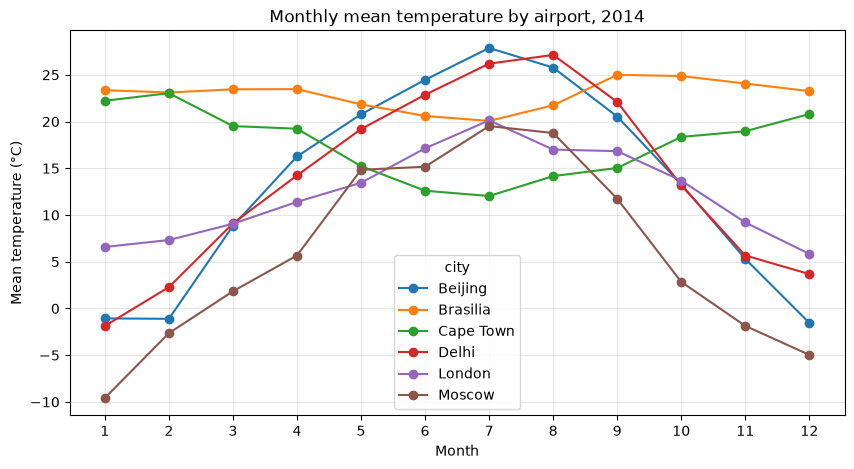

In [85]:
# Monthly mean temperature by city
weather["month"] = weather["GMT"].dt.month
monthly = weather.pivot_table(index="month", columns="city", values="Mean TemperatureC", aggfunc="mean")
ax = monthly.plot(figsize=(10, 5), marker="o")
ax.set_title("Monthly mean temperature by airport, 2014")
ax.set_xlabel("Month"); ax.set_ylabel("Mean temperature (°C)")
ax.set_xticks(range(1, 13)); ax.grid(alpha=.3)
plt.show()

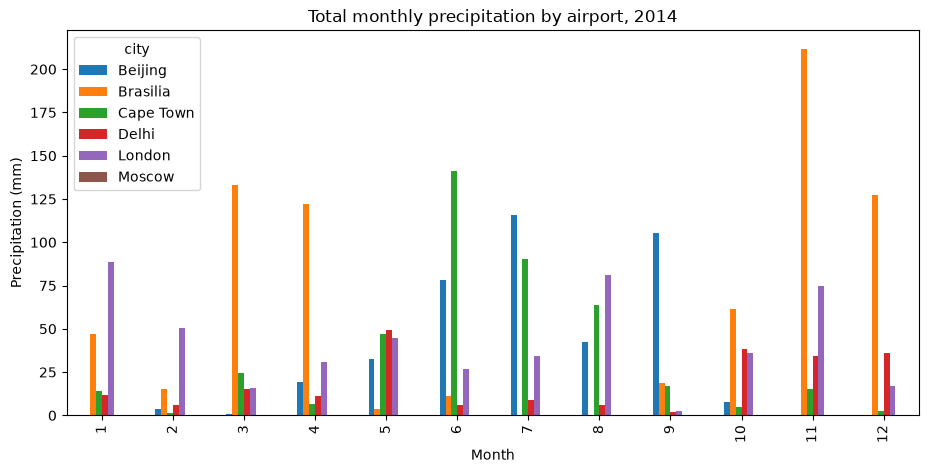

In [86]:
# Monthly precipitation by city
precip = weather.pivot_table(index="month", columns="city", values="Precipitationmm", aggfunc="sum")
ax = precip.plot(kind="bar", figsize=(11, 5))
ax.set_title("Total monthly precipitation by airport, 2014")
ax.set_xlabel("Month"); ax.set_ylabel("Precipitation (mm)")
plt.show()

           daily_range_c  Mean Humidity
city                                   
Beijing             12.0           50.8
Brasilia            10.6           58.1
Cape Town           10.2           68.8
Delhi               13.0           50.6
London               8.0           73.8
Moscow               8.3           73.4


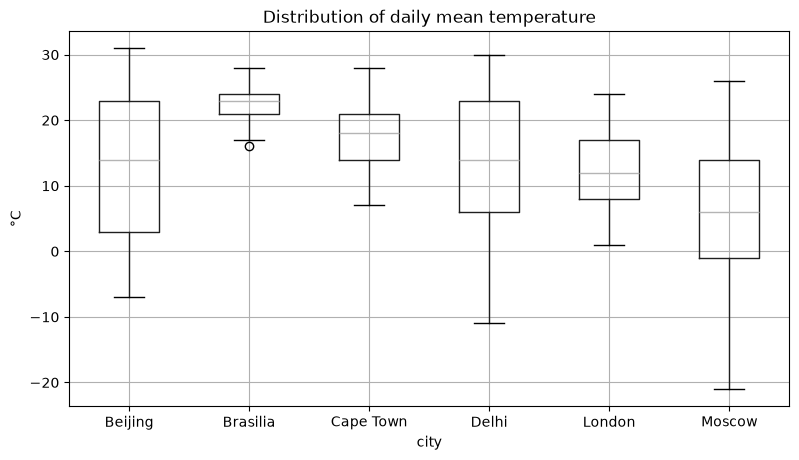

In [87]:
# Temperature spread (daily range) and humidity
weather["daily_range_c"] = weather["Max TemperatureC"] - weather["Min TemperatureC"]
print(weather.groupby("city")[["daily_range_c", "Mean Humidity"]].mean().round(1))

weather.boxplot(column="Mean TemperatureC", by="city", figsize=(9, 5))
plt.suptitle(""); plt.title("Distribution of daily mean temperature"); plt.ylabel("°C")
plt.show()

### Findings: six airports, 2014

**Temperature**
- **Brasília is the warmest city** (mean 22.9 °C) and **Moscow the coldest** (6.0 °C). London (12.3 °C), Beijing (13.4 °C) and Delhi (13.7 °C) are close together, and Cape Town sits at 17.6 °C.
- Brasília is also the most stable: its monthly mean stays roughly between 20 and 25 °C all year (tropical, little seasonal change).
- Moscow has the biggest seasonal swing, from about −10 °C in January to about 20 °C in July. Beijing also swings widely (about −1 °C to 28 °C).
- **Hemispheres:** Cape Town's curve is the mirror image of the northern cities. It is warmest in January–February and coolest in June–July, while Beijing, London and Moscow peak in July.

**Rain**
- **Brasília is the wettest** (about 752 mm), with a clear wet season from November to April (peak of about 210 mm in November) and a dry season from June to September.
- **Cape Town's rain falls in winter** (peak of about 140 mm in June), the opposite of Beijing, whose rain is concentrated in summer (June to September, with a peak of about 115 mm in July).
- **London has the most rainy days (170)** but only about 503 mm in total, which means frequent, lighter rain spread across the whole year.

**Humidity and daily range**
- London (73.8%) and Moscow (73.4%) are the most humid, and Beijing and Delhi (about 51%) the driest.
- Delhi (13.0 °C) and Beijing (12.0 °C) have the largest day-to-night temperature range, and London the smallest (8.0 °C).

**Data quality issues**
- **Moscow shows 0 mm of precipitation and 0 rainy days all year.** Moscow is not a dry city, so this is almost certainly missing or unrecorded data, not a real result. Moscow's rain comparison cannot be trusted.
- **Delhi's temperatures look wrong.** The minimum is −17 °C and the January mean is about −2 °C, which is not realistic for Delhi, and its total rain (225 mm) has almost no monsoon peak. I would flag this table to the data owner before using it.
- Many missing values: `Max Gust SpeedKm/h` (1,604 of 2,190), `Events` (1,211), `CloudCover` (432) and the visibility columns (34 each). Missing `Events` often means "no event recorded", not "unknown".
- Column names have stray spaces, one column name ends in an HTML `<br />` tag, and the date column is called `Date` in five tables but `GMT` in London.

---
## SQL Assessment (Intermediate SQL)

This part tests what you learnt in **`4-Intermediate SQL/Intermediate SQL.ipynb`**. Every task runs against the
**live cohort database** using your **read-only** account.

**How it works**
1. Run the **SQL setup** cell below first (and again after restarting the kernel).
2. In each task cell, write your query **between the triple quotes**, then run the cell.
3. `answer(...)` runs your query, shows the result, and tells you if it's ✅ correct. If not, it tells you
   whether the **shape** (rows × columns) is right, so you know where to look.
4. Match the **column order**, **sort order** and **rounding** asked for. Column *names* aren't checked,
   but use the names given.
5. Run `sql_score()` at the end to see your SQL score.

Writes are blocked: the database is read-only, so build everything inside your `SELECT` (CTEs are your workspace).

In [88]:
# --- SQL setup: run this cell first (don't edit it) ---
import sys, pathlib, re, json, hashlib, datetime, math
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query
import pandas as pd

_BLOCKED = re.compile(r"\b(INSERT|UPDATE|DELETE|MERGE|DROP|ALTER|CREATE|TRUNCATE|EXEC|EXECUTE|GRANT|REVOKE|DENY|INTO|BACKUP|RESTORE)\b", re.I)

def _strip(sql):
    sql = re.sub(r"'([^']|'')*'", "''", sql)
    sql = re.sub(r"--[^\n]*", "", sql)
    return re.sub(r"/\*.*?\*/", "", sql, flags=re.S)

def q(sql):
    """Run a read-only query and return a DataFrame (same helper as the Intermediate SQL notebook)."""
    hit = _BLOCKED.search(_strip(sql))
    if hit:
        raise PermissionError(f"'{hit.group(0).upper()}' is not allowed: the database is read-only.")
    return run_query(sql)

_DATE = re.compile(r"^\d{4}-\d{1,2}-\d{1,2}")

def _norm(v):
    if v is None or (isinstance(v, float) and math.isnan(v)):
        return None
    if isinstance(v, (datetime.date, datetime.datetime, pd.Timestamp)):
        return pd.Timestamp(v).date().isoformat()
    if isinstance(v, str):
        v = v.strip()
        if _DATE.match(v):
            try:
                return pd.Timestamp(v).date().isoformat()
            except ValueError:
                pass
        return v
    try:
        return round(float(v), 2)
    except (TypeError, ValueError):
        return str(v)

def _fingerprint(df):
    rows = [[_norm(v) for v in row] for row in df.itertuples(index=False)]
    return hashlib.sha256(json.dumps(rows).encode()).hexdigest()

# expected answers are stored only as fingerprints, so this notebook doesn't give them away
EXPECTED = {
 "s01": [
  [
   8,
   2
  ],
  "0ba3b4c0210bb324982933cd308c7ff0bb3fbbea32fc6646d9e9e2a9bb14df70"
 ],
 "s02": [
  [
   1,
   3
  ],
  "1512ef1d7254b2206516b1f4bb9dea659b456cab8b80402f5bf67de186fc7fff"
 ],
 "s03": [
  [
   3,
   4
  ],
  "607a2a3b80c9fdc820855d34f48730b445d9437842569c3d7406962b2ec71409"
 ],
 "s04": [
  [
   26,
   2
  ],
  "2fe50527877da0fd0064e1512aa038aa08109668d30b5e0083874edc03b773cf"
 ],
 "s05": [
  [
   5,
   2
  ],
  "8d5b93be4960cbb6acd605b1fa741b3be8bbe6c44c5fb19b843daf38737e1ab1"
 ],
 "s06": [
  [
   1,
   1
  ],
  "c3c32ce95ec239c2ac639584925dced87cfb17b11bee9b738bc7ed104c2ce931"
 ],
 "s07": [
  [
   6,
   2
  ],
  "8450a870c23b5bfab2a420e0a10a1b534e113a7c4acd0be5b90060f8bebe4e2c"
 ],
 "s08": [
  [
   12,
   3
  ],
  "27236391b69c4478be3e09fa08b89fe7c5acd46b03bb5a934c14e6e122bddb0d"
 ],
 "s09": [
  [
   12,
   3
  ],
  "880e60a4b694da3e224b104c67139870b74671f6ef86f16b9d5ac46c2d81ad04"
 ],
 "s10": [
  [
   3,
   4
  ],
  "9b15fac9c91f6a72150b0c1705f96f0e8281cbe86e49c56d49f37a3d885328ac"
 ]
}
TASKS = {
 "s01": "Exploring the schema",
 "s02": "Filtering & NULLs",
 "s03": "CASE & conditional aggregation",
 "s04": "GROUP BY + HAVING",
 "s05": "JOIN across sources",
 "s06": "Anti-join",
 "s07": "UNION ALL",
 "s08": "CTE + window ranking",
 "s09": "Running total (window)",
 "s10": "Business question"
}
RESULTS = {}

def answer(task, sql):
    """Run your query for a task, show the result, and check it."""
    shape, fp = EXPECTED[task]
    if not _strip(sql).strip():
        RESULTS[task] = None
        print(f"⏳ {task}: not attempted yet. Write your query between the triple quotes.")
        return
    try:
        df = q(sql)
    except Exception as err:
        RESULTS[task] = False
        print(f"❌ {task}: the query failed.\n   {type(err).__name__}: {str(err)[:300]}")
        return
    display(df.head(15))
    ok = _fingerprint(df) == fp
    RESULTS[task] = ok
    if ok:
        print(f"✅ {task}: correct!")
        return
    print(f"❌ {task}: not quite. Expected {shape[0]} row(s) × {shape[1]} column(s); "
          f"you returned {df.shape[0]} × {df.shape[1]}.")
    if df.shape == tuple(shape):
        print("   The shape is right, so check: column order, sort order, rounding, and filters "
              "(NULLs, the 'World' row, etc.).")

def sql_score():
    """Print your SQL score table."""
    rows = []
    for task, title in TASKS.items():
        r = RESULTS.get(task)
        rows.append([task, title, "✅" if r else ("not attempted" if r is None else "❌")])
    table = pd.DataFrame(rows, columns=["Task", "Topic", "Result"])
    print(table.to_string(index=False))
    print(f"\nSQL score: {sum(1 for r in RESULTS.values() if r)} / {len(TASKS)}")

print(f"SQL setup done: {len(TASKS)} tasks. Connected as:",
      run_query("SELECT CURRENT_USER AS u").u[0])

SQL setup done: 10 tasks. Connected as: intern_readonly


In [89]:
# Helper: look up the exact column names before writing the queries that use them
cols = q("""
SELECT TABLE_SCHEMA, TABLE_NAME, COLUMN_NAME, DATA_TYPE
FROM INFORMATION_SCHEMA.COLUMNS
WHERE (TABLE_SCHEMA = 'week06' AND TABLE_NAME IN ('who_pop_tb_all','london_2014'))
   OR (TABLE_SCHEMA = 'week08' AND TABLE_NAME = 'wb_pop_2013')
   OR (TABLE_SCHEMA = 'week09' AND TABLE_NAME = 'comtrade_milk_uk_monthly_14')
   OR (TABLE_SCHEMA = 'week16' AND TABLE_NAME = 'customer_churn_prediction')
   OR (TABLE_SCHEMA = 'week17' AND TABLE_NAME = 'loan_approval_prediction')
ORDER BY TABLE_SCHEMA, TABLE_NAME, ORDINAL_POSITION
""")
cols

,TABLE_SCHEMA,TABLE_NAME,COLUMN_NAME,DATA_TYPE
0,week06,london_2014,GMT,varchar
1,week06,london_2014,Max TemperatureC,bigint
2,week06,london_2014,Mean TemperatureC,bigint
3,week06,london_2014,Min TemperatureC,bigint
4,week06,london_2014,Dew PointC,bigint
...,...,...,...,...
94,week17,loan_approval_prediction,Property_Area,varchar
95,week17,loan_approval_prediction,Previous_Loan_Status,varchar
96,week17,loan_approval_prediction,Employment_Years,bigint
97,week17,loan_approval_prediction,Age,bigint


### SQL Task 1 · Exploring the schema
Using `INFORMATION_SCHEMA.COLUMNS`, list every table in the **`week06`** schema with **how many columns** it has.

**Return:** `table_name`, `n_columns`, sorted by `table_name` (A→Z).
*Revisit: Intermediate SQL §1.*

In [90]:
SQL_01 = """
SELECT TABLE_NAME AS table_name,
       COUNT(*)   AS n_columns
FROM INFORMATION_SCHEMA.COLUMNS
WHERE TABLE_SCHEMA = 'week06'
GROUP BY TABLE_NAME
ORDER BY TABLE_NAME
"""
answer("s01", SQL_01)

,table_name,n_columns
0,beijing_pek_2014,23
1,brasilia_bsb_2014,23
2,capetown_cpt_2014,23
3,delhi_del_2014,23
4,london_2014,23
5,moscow_svo_2014,23
6,who_pop_tb_all,3
7,who_pop_tb_some,3


✅ s01: correct!


### SQL Task 2 · Filtering & NULLs
For **London** (`week06.london_2014`), return **one row** with three counts:
1. `no_event_days`: days with **no event recorded**
2. `rain_days`: days whose event mentions **Rain** anywhere (e.g. `Rain`, `Fog-Rain`, `Rain-Thunderstorm`)
3. `wet_but_no_event_days`: days with **no event recorded** but `Precipitationmm > 0`

⚠️ The events column name starts with a **space**: `[ Events]`. And remember, `= NULL` never matches.
*Revisit: §1.2, §3.2, §3.3.*

In [91]:
SQL_02 = """
SELECT
    SUM(CASE WHEN [ Events] IS NULL THEN 1 ELSE 0 END)                          AS no_event_days,
    SUM(CASE WHEN [ Events] LIKE '%Rain%' THEN 1 ELSE 0 END)                    AS rain_days,
    SUM(CASE WHEN [ Events] IS NULL AND Precipitationmm > 0 THEN 1 ELSE 0 END)  AS wet_but_no_event_days
FROM week06.london_2014
"""
answer("s02", SQL_02)

,no_event_days,rain_days,wet_but_no_event_days
0,114,238,6


✅ s02: correct!


### SQL Task 3 · CASE & conditional aggregation
From `week16.customer_churn_prediction`, for each `Contract_Type` return: number of `customers`, number
`churned` (`Churn = 1`), and `churn_rate_pct` (percentage, **rounded to 1 decimal place**).

**Return:** `Contract_Type`, `customers`, `churned`, `churn_rate_pct`, sorted by `churn_rate_pct` (highest first).
⚠️ Watch out for the integer-division trap. *Revisit: §4.4, §5.2.*

In [92]:
SQL_03 = """
SELECT Contract_Type,
       COUNT(*) AS customers,
       SUM(CASE WHEN Churn = 1 THEN 1 ELSE 0 END) AS churned,
       ROUND(100.0 * SUM(CASE WHEN Churn = 1 THEN 1 ELSE 0 END) / COUNT(*), 1) AS churn_rate_pct   -- 100.0 avoids integer division
FROM week16.customer_churn_prediction
GROUP BY Contract_Type
ORDER BY churn_rate_pct DESC
"""
answer("s03", SQL_03)

,Contract_Type,customers,churned,churn_rate_pct
0,Month-to-Month,158,91,57.6
1,One Year,165,89,53.9
2,Two Year,177,48,27.1


✅ s03: correct!


### SQL Task 4 · GROUP BY + HAVING
From `week09.comtrade_milk_uk_monthly_14`, find the partner countries the UK **exported** milk to in
**all 12 months** of 2014, with the **total export value**.

**Return:** `Partner`, `total_exports_usd`, sorted by `total_exports_usd` (highest first).
⚠️ Exclude the `'World'` total row. *Revisit: §6.2.*

In [94]:
# Column names of the table
display(run_query("""
SELECT COLUMN_NAME, DATA_TYPE
FROM INFORMATION_SCHEMA.COLUMNS
WHERE TABLE_SCHEMA = 'week09' AND TABLE_NAME = 'comtrade_milk_uk_monthly_14'
ORDER BY ORDINAL_POSITION
"""))

# What values does Trade Flow hold?
display(run_query("""
SELECT [Trade Flow], COUNT(*) AS n
FROM week09.comtrade_milk_uk_monthly_14
GROUP BY [Trade Flow]
"""))

# What do Period and Partner look like?
display(run_query("""
SELECT TOP 15 Period, Partner, [Trade Flow], [Trade Value (US$)]
FROM week09.comtrade_milk_uk_monthly_14
ORDER BY Partner, Period
"""))

# How many months does each partner have?
display(run_query("""
SELECT COUNT(DISTINCT Period) AS months, COUNT(*) AS partners
FROM (SELECT Partner, Period FROM week09.comtrade_milk_uk_monthly_14 GROUP BY Partner, Period) t
GROUP BY Partner
"""))

,COLUMN_NAME,DATA_TYPE
0,Classification,varchar
1,Year,bigint
2,Period,bigint
3,Period Desc.,varchar
4,Aggregate Level,bigint
5,Is Leaf Code,bigint
6,Trade Flow Code,bigint
7,Trade Flow,varchar
8,Reporter Code,varchar
9,Reporter,varchar


,Trade Flow,n
0,Exports,1118
1,Imports,359


,Period,Partner,Trade Flow,Trade Value (US$)
0,201401,Afghanistan,Exports,3410
1,201402,Afghanistan,Exports,13481
2,201403,Afghanistan,Exports,4467
3,201405,Afghanistan,Exports,15999
4,201406,Afghanistan,Exports,13150
5,201407,Afghanistan,Exports,4017
6,201401,Algeria,Exports,4792662
7,201402,Algeria,Exports,7220679
8,201403,Algeria,Exports,9835523
9,201404,Algeria,Exports,14875816


,months,partners
0,6,6
1,12,12
2,11,11
3,9,9
4,5,5
...,...,...
116,12,12
117,12,12
118,12,12
119,8,8


In [95]:
SQL_04 = """
SELECT Partner,
       SUM([Trade Value (US$)]) AS total_exports_usd
FROM week09.comtrade_milk_uk_monthly_14
WHERE [Trade Flow] = 'Exports'
  AND Partner <> 'World'
GROUP BY Partner
HAVING COUNT(DISTINCT Period) = 12
ORDER BY total_exports_usd DESC
"""
answer("s04", SQL_04)

,Partner,total_exports_usd
0,Ireland,421228441
1,Algeria,93753841
2,Netherlands,68649082
3,Germany,36096633
4,France,34622982
5,Belgium,29343007
6,China,27317861
7,"China, Hong Kong SAR",19847947
8,Nigeria,12932371
9,Guinea,12018176


✅ s04: correct!


### SQL Task 5 · JOIN across two sources
Join WHO TB data (`week06.who_pop_tb_all`) with World Bank population (`week08.wb_pop_2013`) on the country
name. Compute **TB deaths per 100,000 people** using the **World Bank** population (`[SP.POP.TOTL]`),
**rounded to 1 decimal place**.

**Return:** the **top 5** countries: `Country`, `tb_deaths_per_100k`, highest first.
*Revisit: §7.2–7.3.*

In [97]:
# 1. Which tables exist in week08?
display(run_query("""
SELECT TABLE_SCHEMA, TABLE_NAME
FROM INFORMATION_SCHEMA.TABLES
WHERE TABLE_SCHEMA = 'week08'
ORDER BY TABLE_NAME
"""))

# 2. Columns of every table in week08
display(run_query("""
SELECT TABLE_NAME, COLUMN_NAME, DATA_TYPE
FROM INFORMATION_SCHEMA.COLUMNS
WHERE TABLE_SCHEMA = 'week08'
ORDER BY TABLE_NAME, ORDINAL_POSITION
"""))

,TABLE_SCHEMA,TABLE_NAME
0,week08,wb_gdp_2013
1,week08,wb_le_2013
2,week08,wb_pop_2013


,TABLE_NAME,COLUMN_NAME,DATA_TYPE
0,wb_gdp_2013,country,varchar
1,wb_gdp_2013,year,bigint
2,wb_gdp_2013,NY.GDP.MKTP.CD,float
3,wb_le_2013,country,varchar
4,wb_le_2013,year,bigint
5,wb_le_2013,SP.DYN.LE00.IN,float
6,wb_pop_2013,country,varchar
7,wb_pop_2013,year,bigint
8,wb_pop_2013,SP.POP.TOTL,float


In [98]:
SQL_05 = """
SELECT TOP 5
       w.Country,
       ROUND(w.[TB deaths] * 100000.0 / b.[SP.POP.TOTL], 1) AS tb_deaths_per_100k
FROM week06.who_pop_tb_all AS w
JOIN week08.wb_pop_2013 AS b
  ON w.Country = b.country
ORDER BY tb_deaths_per_100k DESC
"""
answer("s05", SQL_05)

,Country,tb_deaths_per_100k
0,Djibouti,100.6
1,Nigeria,92.6
2,Swaziland,88.0
3,Timor-Leste,83.9
4,Somalia,75.0


✅ s05: correct!


### SQL Task 6 · Anti-join
How many WHO countries in `week06.who_pop_tb_all` have **no matching country name** in `week08.wb_pop_2013`?

**Return:** one row, one column (`who_countries_without_wb_match`).
*Revisit: §7.4. Bonus thought: why do these countries fail to match?*

In [100]:
SQL_06 = """
SELECT COUNT(*) AS who_countries_without_wb_match
FROM week06.who_pop_tb_all AS w
WHERE NOT EXISTS (
    SELECT 1 FROM week08.wb_pop_2013 AS b
    WHERE b.country = w.Country
)
"""
answer("s06", SQL_06)

,who_countries_without_wb_match
0,28


✅ s06: correct!


### SQL Task 7 · UNION ALL
Stack the **six** city weather tables in `week06` and compute each city's **average `Mean TemperatureC`**
for 2014, **rounded to 1 decimal place**. Use exactly these city labels:
`'Beijing'`, `'Brasilia'`, `'Cape Town'`, `'Delhi'`, `'London'`, `'Moscow'`.

**Return:** `city`, `avg_mean_temp_c`, sorted by `city` (A→Z).
⚠️ `Mean TemperatureC` is stored as a whole number, so watch the integer-division trap. *Revisit: §8.1–8.2.*

In [101]:
SQL_07 = """
WITH all_cities AS (
    SELECT 'Beijing'   AS city, [Mean TemperatureC] AS t FROM week06.beijing_pek_2014
    UNION ALL SELECT 'Brasilia',  [Mean TemperatureC] FROM week06.brasilia_bsb_2014
    UNION ALL SELECT 'Cape Town', [Mean TemperatureC] FROM week06.capetown_cpt_2014
    UNION ALL SELECT 'Delhi',     [Mean TemperatureC] FROM week06.delhi_del_2014
    UNION ALL SELECT 'London',    [Mean TemperatureC] FROM week06.london_2014
    UNION ALL SELECT 'Moscow',    [Mean TemperatureC] FROM week06.moscow_svo_2014
)
SELECT city,
       ROUND(AVG(CAST(t AS FLOAT)), 1) AS avg_mean_temp_c   -- CAST avoids integer truncation
FROM all_cities
GROUP BY city
ORDER BY city
"""
answer("s07", SQL_07)

,city,avg_mean_temp_c
0,Beijing,13.4
1,Brasilia,22.9
2,Cape Town,17.6
3,Delhi,13.7
4,London,12.3
5,Moscow,6.0


✅ s07: correct!


### SQL Task 8 · CTE + window ranking (top-1 per group)
For **London**, find the **hottest day of each month** (highest `Max TemperatureC`). If two days tie,
take the **earlier** date.

**Return:** `month_no`, `day` (a real **date**, convert `GMT` with `TRY_CONVERT(date, GMT)`), `max_temp`,
sorted by `month_no`. *Revisit: §10, §11.3.*

In [102]:
SQL_08 = """
WITH ranked AS (
    SELECT MONTH(TRY_CONVERT(date, GMT)) AS month_no,
           TRY_CONVERT(date, GMT)        AS [day],
           [Max TemperatureC]            AS max_temp,
           ROW_NUMBER() OVER (
               PARTITION BY MONTH(TRY_CONVERT(date, GMT))
               ORDER BY [Max TemperatureC] DESC, TRY_CONVERT(date, GMT) ASC   -- ties -> earlier date
           ) AS rn
    FROM week06.london_2014
)
SELECT month_no, [day], max_temp
FROM ranked
WHERE rn = 1
ORDER BY month_no
"""
answer("s08", SQL_08)

,month_no,day,max_temp
0,1,2014-01-05,12
1,2,2014-02-24,14
2,3,2014-03-09,19
3,4,2014-04-01,19
4,5,2014-05-19,26
5,6,2014-06-09,26
6,7,2014-07-18,30
7,8,2014-08-06,26
8,9,2014-09-18,26
9,10,2014-10-31,23


✅ s08: correct!


### SQL Task 9 · Running total
From `week09.comtrade_milk_uk_monthly_14`, compute the UK's **total milk exports per month** (exclude `'World'`)
and a **year-to-date running total**.

**Return:** `Period`, `exports_usd`, `ytd_exports_usd`, sorted by `Period`. *Revisit: §11.4–11.5.*

In [104]:
SQL_09 = """
WITH monthly AS (
    SELECT Period, SUM([Trade Value (US$)]) AS exports_usd
    FROM week09.comtrade_milk_uk_monthly_14
    WHERE [Trade Flow] = 'Exports'
      AND Partner <> 'World'
    GROUP BY Period
)
SELECT Period,
       exports_usd,
       SUM(exports_usd) OVER (ORDER BY Period ROWS UNBOUNDED PRECEDING) AS ytd_exports_usd
FROM monthly
ORDER BY Period
"""
answer("s09", SQL_09)

,Period,exports_usd,ytd_exports_usd
0,201401,87138654,87138654
1,201402,72489716,159628370
2,201403,86781424,246409794
3,201404,95195778,341605572
4,201405,96201135,437806707
5,201406,99315900,537122607
6,201407,72878716,610001323
7,201408,61737703,671739026
8,201409,60600293,732339319
9,201410,57003417,789342736


✅ s09: correct!


### SQL Task 10 · Business question
The Head of Credit asks: *"How does the approval rate vary by property area and credit history?"*
Using `week17.loan_approval_prediction`, return one row per `Property_Area` × `Credit_History` combination
that exists in the data, with the number of `applications` and the `approval_rate_pct` (rounded to 1 decimal).

**Return:** `Property_Area`, `Credit_History`, `applications`, `approval_rate_pct`, sorted by `Property_Area`
then `Credit_History`. Then answer reflection question 3 below about what you see.

In [106]:
# 1. Which tables are in week17?
display(run_query("""
SELECT TABLE_NAME
FROM INFORMATION_SCHEMA.TABLES
WHERE TABLE_SCHEMA = 'week17'
ORDER BY TABLE_NAME
"""))

# 2. Their columns
display(run_query("""
SELECT TABLE_NAME, COLUMN_NAME, DATA_TYPE
FROM INFORMATION_SCHEMA.COLUMNS
WHERE TABLE_SCHEMA = 'week17'
ORDER BY TABLE_NAME, ORDINAL_POSITION
"""))

# 3. The actual error text
try:
    run_query(SQL_10)
except Exception as e:
    print(str(e)[-500:])

,TABLE_NAME
0,assignment1_product_recommendation
1,assignment2_medical_diagnosis
2,assignment3_classifier_comparison
3,customer_list
4,loan_approval_prediction
5,task1_knn_customer_data
6,task2_svm_classification_data
7,task3_naive_bayes_data


,TABLE_NAME,COLUMN_NAME,DATA_TYPE
0,assignment1_product_recommendation,Customer_ID,bigint
1,assignment1_product_recommendation,Age,bigint
2,assignment1_product_recommendation,Annual_Income,bigint
3,assignment1_product_recommendation,Spending_Score,bigint
4,assignment1_product_recommendation,Purchase_Frequency,bigint
...,...,...,...
56,task3_naive_bayes_data,Link_Count,bigint
57,task3_naive_bayes_data,Uppercase_Ratio,float
58,task3_naive_bayes_data,Special_Char_Count,bigint
59,task3_naive_bayes_data,Contains_Urgent,bigint


 messages from the SQL Server\n")
[SQL: 
-- Assumes Loan_Status holds 'Y' / 'N'. If it is 1 / 0, change the condition to Loan_Status = 1
SELECT Property_Area,
       Credit_History,
       COUNT(*) AS applications,
       ROUND(100.0 * SUM(CASE WHEN Loan_Status = 'Y' THEN 1 ELSE 0 END) / COUNT(*), 1) AS approval_rate_pct
FROM week17.loan_approval_prediction
GROUP BY Property_Area, Credit_History
ORDER BY Property_Area, Credit_History
]
(Background on this error at: https://sqlalche.me/e/21/f405)


In [107]:
# Columns of just the loan table
display(run_query("""
SELECT COLUMN_NAME, DATA_TYPE
FROM INFORMATION_SCHEMA.COLUMNS
WHERE TABLE_SCHEMA = 'week17' AND TABLE_NAME = 'loan_approval_prediction'
ORDER BY ORDINAL_POSITION
"""))

# A few rows, to see the real values
display(run_query("SELECT TOP 5 * FROM week17.loan_approval_prediction"))

# The actual error message (the useful part is near the start)
try:
    run_query(SQL_10)
except Exception as e:
    print(str(e)[:600])

,COLUMN_NAME,DATA_TYPE
0,Application_ID,bigint
1,Gender,varchar
2,Married,varchar
3,Dependents,bigint
4,Education,varchar
5,Self_Employed,varchar
6,Applicant_Income,bigint
7,Coapplicant_Income,bigint
8,Loan_Amount,bigint
9,Loan_Term,bigint


,Application_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Term,Credit_History,Property_Area,Previous_Loan_Status,Employment_Years,Age,Loan_Approved
0,1,Male,Yes,2,Graduate,No,45000,15000,150000,360,1,Urban,Paid,8,35,1
1,2,Female,No,0,Graduate,No,38000,0,95000,180,1,Semiurban,NaN,5,28,1
2,3,Male,Yes,1,Not Graduate,Yes,28000,8000,85000,360,0,Rural,Defaulted,3,42,0
3,4,Female,Yes,3,Graduate,No,62000,22000,280000,360,1,Urban,Paid,12,45,1
4,5,Male,No,0,Graduate,No,32000,0,78000,240,1,Semiurban,NaN,4,26,1


Execution failed on sql '
-- Assumes Loan_Status holds 'Y' / 'N'. If it is 1 / 0, change the condition to Loan_Status = 1
SELECT Property_Area,
       Credit_History,
       COUNT(*) AS applications,
       ROUND(100.0 * SUM(CASE WHEN Loan_Status = 'Y' THEN 1 ELSE 0 END) / COUNT(*), 1) AS approval_rate_pct
FROM week17.loan_approval_prediction
GROUP BY Property_Area, Credit_History
ORDER BY Property_Area, Credit_History
': (pymssql.exceptions.ProgrammingError) (207, b"Invalid column name 'Loan_Status'.DB-Lib error message 20018, severity 16:\nGeneral SQL Server error: Check messages from the SQ


In [109]:
SQL_10 = """
SELECT Property_Area,
       Credit_History,
       COUNT(*) AS applications,
       ROUND(100.0 * SUM(CASE WHEN Loan_Approved = 1 THEN 1 ELSE 0 END) / COUNT(*), 1) AS approval_rate_pct
FROM week17.loan_approval_prediction
GROUP BY Property_Area, Credit_History
ORDER BY Property_Area, Credit_History
"""
answer("s10", SQL_10)

,Property_Area,Credit_History,applications,approval_rate_pct
0,Rural,0,166,0.0
1,Semiurban,1,167,100.0
2,Urban,1,167,100.0


✅ s10: correct!


### SQL reflection
Answer in the cell below (2–3 sentences each):

1. In Task 3 or Task 7, what would `AVG(Churn)` or `AVG([Mean TemperatureC])` return **without** converting to a
   decimal first, and why?
2. In Task 6, why do those countries fail to match? How would you fix this in a real project?
3. Look at your Task 10 result. What is **suspicious** about it? What would you tell the Head of Credit before
   anyone trains a model on this data?

**My answers:**

1. Without converting, SQL Server's `AVG` on an integer column does **integer arithmetic** and truncates the result. `AVG(Churn)` over 0/1 values would return `0` (or `1`) instead of something like `0.27`, and `AVG([Mean TemperatureC])` would return a whole number such as `11` instead of `11.4`. This is because int ÷ int gives int in T-SQL. Casting first (`CAST(x AS FLOAT)`) or multiplying by `1.0` / `100.0` forces decimal division.
2. The names are written differently in the two sources, so an exact string match fails. Typical cases are "Russian Federation" vs "Russia", "Viet Nam" vs "Vietnam", "Republic of Korea" vs "Korea, Rep.", and the "United States of America" vs "United States" pair, plus regions and territories that only one source includes. In a real project I would not join on free-text names. I would join on a standard key such as the ISO 3166 country code, or build a small mapping table for the mismatches, and I would review the anti-join list manually to check which are naming issues and which are genuinely missing.
3. `Credit_History` appears to decide the outcome completely. Every application with `Credit_History = 0` was rejected (0% approved, 166 applications, all Rural), and every application with `Credit_History = 1` was approved (100% approved, 167 Urban and 167 Semiurban). Property_Area and Credit_History never overlap, so their effects cannot be separated: an apparent "Rural penalty" is really credit history, and the data cannot tell us what would happen to a Rural applicant with a good credit history. Rates of exactly 0% and 100% are unrealistic for real lending, so I would tell the Head of Credit that this data looks synthetic, rule-generated or leaking the decision into the features. Before anyone builds a model we should check how and when Credit_History was recorded, whether Rural applicants are treated unfairly, and ask for data that includes every combination of area and credit history.


### SQL score
Run this when you're done.

In [111]:
sql_score()

Task                          Topic Result
 s01           Exploring the schema      ✅
 s02              Filtering & NULLs      ✅
 s03 CASE & conditional aggregation      ✅
 s04              GROUP BY + HAVING      ✅
 s05            JOIN across sources      ✅
 s06                      Anti-join      ✅
 s07                      UNION ALL      ✅
 s08           CTE + window ranking      ✅
 s09         Running total (window)      ✅
 s10              Business question      ✅

SQL score: 10 / 10


---
## 📰 Article Link

Write a **detailed article** about this week's work. It should cover:

- **What you learnt:** the key concepts, tools and techniques from this week.
- **What you solved:** the tasks and projects you worked on, and how you approached them.
- **Challenges you faced:** what was hard, confusing or didn't work at first.
- **How you overcame them:** what you tried, what finally worked, and what you'd do differently.
- **Anything else you want to share:** insights, results, visuals, or advice for others learning this.

Publish it, then paste the article's **URL** in the empty cell below (double-click the cell to edit it).